# Student Scores – Mini Research Project

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


np.random.seed(42)
n = 5000
data = pd.DataFrame({
    "Student_ID": np.arange(1, n + 1),
    "Age": np.random.randint(16, 25, n),
    "Hours_Studied": np.clip(np.random.normal(5.5, 2, n), 0.5, 12).round(1)
})
data["Math_Score"] = np.clip(38 + 5.2*data["Hours_Studied"] + np.random.normal(0,11,n),0,100).round(1)
data["Science_Score"] = np.clip(35 + 5.0*data["Hours_Studied"] + np.random.normal(0,12,n),0,100).round(1)
data["English_Score"] = np.clip(42 + 4.2*data["Hours_Studied"] + np.random.normal(0,11,n),0,100).round(1)
average_score = data[["Math_Score","Science_Score","English_Score"]].mean(axis=1)
data["Pass_Fail"] = (average_score >= 50).astype(int)
data.to_csv("students_scores.csv", index=False)
print(data.head())
print("Dataset shape:", data.shape)


   Student_ID  Age  Hours_Studied  Math_Score  Science_Score  English_Score  \
0           1   22            4.4        79.7           53.0           55.3   
1           2   19            9.7        99.8           96.0           89.5   
2           3   23            7.6        81.6           71.0           86.7   
3           4   20            8.6        62.2           71.0           66.7   
4           5   22            4.2        52.1           53.0           68.7   

   Pass_Fail  
0          1  
1          1  
2          1  
3          1  
4          1  
Dataset shape: (5000, 7)


### Measures of Central Tendency and Dispersion

In [24]:
print("MATH SCORE")
print("Mean:", data["Math_Score"].mean())
print("Median:", data["Math_Score"].median())
print("Mode:", data["Math_Score"].mode().iloc[0])

print("\\nSCIENCE SCORE")
print("Range:", data["Science_Score"].max() - data["Science_Score"].min())
print("Variance:", data["Science_Score"].var())       
print("Standard Deviation:", data["Science_Score"].std())  # sample standard deviation


MATH SCORE
Mean: 66.48903999999999
Median: 66.3
Mode: 100.0
\nSCIENCE SCORE
Range: 95.3
Variance: 227.14592802560523
Standard Deviation: 15.071361186887044


### Probability Basics

In [25]:
prob_pass = (data["Pass_Fail"] == 1).mean()
print("P(Pass_Fail = 1):", prob_pass)

data["Hours_Studied_GT_5"] = data["Hours_Studied"] > 5
contingency_table = pd.crosstab(data["Pass_Fail"], data["Hours_Studied_GT_5"])
print(contingency_table)

# P(Pass | Hours_Studied > 5)
subset = data[data["Hours_Studied"] > 5]
conditional_probability = (subset["Pass_Fail"] == 1).mean()
print("P(Pass | Hours_Studied > 5):", conditional_probability)


P(Pass_Fail = 1): 0.8998
Hours_Studied_GT_5  False  True 
Pass_Fail                       
0                     489     12
1                    1561   2938
P(Pass | Hours_Studied > 5): 0.9959322033898305


### Distribution and Visualization

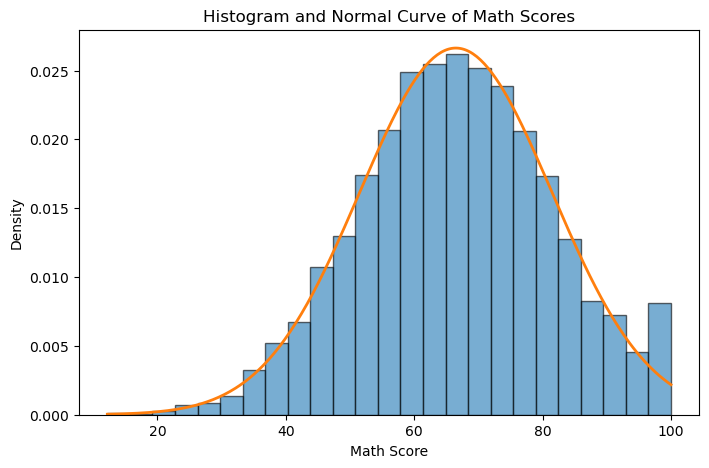

Science Skewness: -0.10886282970156567
Science Kurtosis (excess): -0.07023057793232246


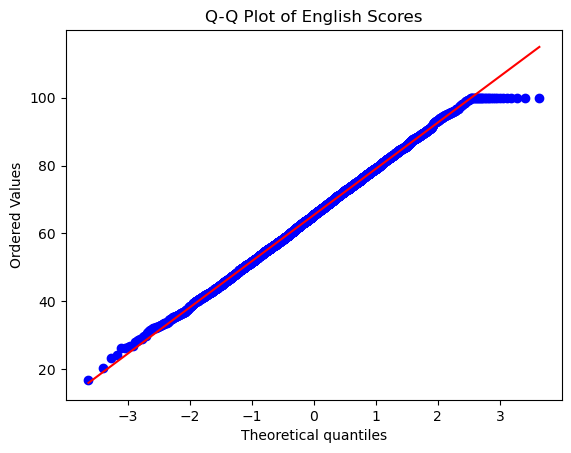

In [26]:
math_mean = data["Math_Score"].mean()
math_sd = data["Math_Score"].std()
plt.figure(figsize=(8,5))
plt.hist(data["Math_Score"], bins=25, density=True, alpha=0.6, edgecolor="black")
x = np.linspace(data["Math_Score"].min(), data["Math_Score"].max(), 300)
plt.plot(x, stats.norm.pdf(x, math_mean, math_sd), linewidth=2)
plt.title("Histogram and Normal Curve of Math Scores")
plt.xlabel("Math Score"); plt.ylabel("Density"); plt.show()

print("Science Skewness:", data["Science_Score"].skew())
print("Science Kurtosis (excess):", data["Science_Score"].kurt())

stats.probplot(data["English_Score"], dist="norm", plot=plt)
plt.title("Q-Q Plot of English Scores")
plt.show()


### Linear Algebra Mini Task

In [27]:
math_vector = data["Math_Score"].head(5).to_numpy()
science_vector = data["Science_Score"].head(5).to_numpy()
print("Math vector:", math_vector)
print("Science vector:", science_vector)

dot_product = np.dot(math_vector, science_vector)
norm1 = np.linalg.norm(math_vector, ord=1)  # L1 norm
norm2 = np.linalg.norm(math_vector, ord=2)  # L2 norm
cos_theta = dot_product / (np.linalg.norm(math_vector) * np.linalg.norm(science_vector))
cos_theta = np.clip(cos_theta, -1, 1)
angle = np.degrees(np.arccos(cos_theta))
print("Dot Product:", dot_product)
print("L1 Norm of Math vector:", norm1)
print("L2 Norm of Math vector:", norm2)
print("Angle between vectors:", angle, "degrees")


Math vector: [79.7 99.8 81.6 62.2 52.1]
Science vector: [53. 96. 71. 71. 53.]
Dot Product: 26776.0
L1 Norm of Math vector: 375.40000000000003
L2 Norm of Math vector: 171.91259407035892
Angle between vectors: 9.344056102439152 degrees


### Extra – Pass/Fail Chart and Findings

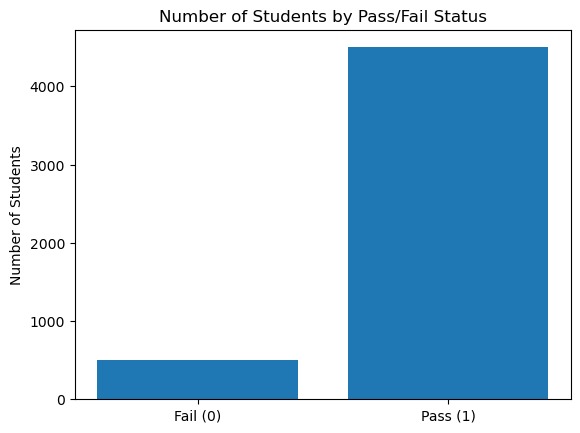

Overall pass probability: 0.8998
Pass probability for students studying > 5 hours: 0.9959322033898305


In [28]:
pass_counts = data["Pass_Fail"].value_counts().sort_index()
plt.bar(["Fail (0)", "Pass (1)"], [pass_counts.get(0,0), pass_counts.get(1,0)])
plt.title("Number of Students by Pass/Fail Status")
plt.ylabel("Number of Students")
plt.show()
print("Overall pass probability:", data["Pass_Fail"].mean())
print("Pass probability for students studying > 5 hours:",
      data.loc[data["Hours_Studied"] > 5, "Pass_Fail"].mean())
